---
title: "Wycena opcji barierowej typu Down-and-Out Put z wykorzystaniem modelowania układów przepływowych"
author: "Kamil Kasperek"
lang: pl
format:
  pdf:
    geometry: margin=0.65in
    fontsize: 10pt
    echo: false
    warning: false
---

### Streszczenie i pytanie badawcze
Przedstawiono numeryczną wycenę europejskiej opcji sprzedaży z dolną barierą wyłączającą (**Down-and-Out Put**) poprzez sformułowanie równania Blacka-Scholesa jako jednowymiarowego zagadnienia adwekcji-dyfuzji i rozwiązanie go za pomocą biblioteki `PyMPDATA`.

**Pytanie badawcze:** *Z jaką dokładnością schemat drugiego rzędu `MPDATA` odwzorowuje stromą warstwę przyścienną przy barierze wyłączającej $B$ — oraz gwałtowny skok wrażliwości portfela ($\Delta = \partial V / \partial S$) — w porównaniu ze schematem pierwszego rzędu `upwind`?*

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA-examples')

In [2]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## 1. Model matematyczny i dyskretyzacja `PyMPDATA`

W modelu Blacka-Scholesa cena $V(S, t)$ opcji europejskiej spełnia równanie różniczkowe cząstkowe:
$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS \frac{\partial V}{\partial S} - rV = 0$$

Po wprowadzeniu zmiennej logarytmicznej $x = \ln(S/K)$, czasu wstecznego $\tau = T - t$ oraz niezdyskontowanej wartości opcji $\psi(x, \tau) = e^{r\tau} V(x, \tau)$ równanie przyjmuje postać jednowymiarowego równania adwekcji-dyfuzji o stałych współczynnikach:
$$\frac{\partial \psi}{\partial \tau} + \underbrace{\left(\frac{1}{2}\sigma^2 - r\right)}_{v_{\text{adv}}} \frac{\partial \psi}{\partial x} = \underbrace{\frac{1}{2}\sigma^2}_{D} \frac{\partial^2 \psi}{\partial x^2}$$

* **Warunek początkowy ($\tau = 0$):** Wypłata w dniu wygaśnięcia tworzy klin $\psi(x, 0) = \max(K - Ke^x, 0)$ dla $x > x_{\min} = \ln(B/K)$ oraz $0$ w pozostałym obszarze.
* **Warunek brzegowy:** Bariera wyłączająca w punkcie $x_{\min}$ działa jak brzeg pochłaniający modelowany jednorodnym warunkiem Dirichleta ($\psi = 0$) na lewej krawędzi pierwszej komórki siatki.
* **Pseudo-prędkość dyfuzyjna:** Człon dyfuzyjny jest realizowany w `PyMPDATA` za pomocą prędkości dyfuzyjnej Smolarkiewicza $v_{\text{diff}} = -D \frac{\partial_x \psi}{\psi + \epsilon}$, z krokiem czasowym $\Delta t$ dobranym tak, aby spełnić warunek stabilności Couranta $|C_{\text{adv}} + C_{\text{diff}}| \le 1$.

In [3]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        
        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.x = x_min + (np.arange(nx) + 0.5) * self.dx
        self.S = self.K * np.exp(self.x)

        payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)
        common = {
            'halo' : options.n_halo,
            'boundary_conditions' : (boundary_conditions.Constant(value=0),)
        }
        
        self.advectee = ScalarField(**common, data=payout)
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(advector=self.advector, advectee=self.advectee, stepper=Stepper(n_dims=1, options=options))

    def _update_courant_numbers(self, *, dt, eps=1e-12):
        psi = self.advectee.get()
        psi_padded = np.pad(psi, 1, constant_values=0.0)
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        lambda_sq = 0.5 * self.sigma**2 * dt / (self.dx**2)
        c_diff = -lambda_sq * np.diff(psi_padded) / (0.5 * (psi_padded[1:] + psi_padded[:-1]) + eps)
        courant = self.advector.get_component(0)
        courant[:] = c_adv + c_diff
        
        assert np.amax(np.abs(courant)) <= 1.0

    def __call__(self, *, nt, T, outfreq, eps=1e-7):
        dt = T / nt
        output = []
        for it in range(nt + 1):
            if it != 0:
                self._update_courant_numbers(dt=dt)
                self.solver.advance(n_steps=1)
            if it % outfreq == 0:
                output.append(self.advectee.get().copy() * np.exp(-self.r * it * dt))
        return output

## 2. Wzorzec analityczny (metoda odbić zwierciadlanych)

Do weryfikacji solwera numerycznego wykorzystano ścisłe rozwiązanie analityczne wyprowadzone metodą odbić zwierciadlanych (Wilmott, Howison i Dewynne, 1995). Niech $V_{\text{trunc}}(S)$ oznacza bezbarierową cenę Blacka-Scholesa opcji sprzedaży przyciętej poniżej bariery $B$ (złożonej z pozycji długiej w opcji Put o cenie wykonania $K$, krótkiej w opcji Put na progu $B$ oraz krótkiej w opcji binarnej o nominale $K - B$ na progu $B$). Wymuszenie warunku $V_{\text{DO}}(B, t) = 0$ prowadzi do wzoru:
$$V_{\text{DO}}(S, 0) = V_{\text{trunc}}(S) - \left(\frac{B}{S}\right)^{\frac{2r}{\sigma^2} - 1} V_{\text{trunc}}\left(\frac{B^2}{S}\right), \quad S > B$$

In [4]:
def AnalyticalDownAndOutPutSolver(S, K, B, T, r, sigma):
    def N(z):
        return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * N(-d2) - s * N(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * N(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

### Funckja do wyświetlania końcowych rezultatów

In [5]:
def plot_results(integ_MPDATA, output_MPDATA, output_upwind):
    S = integ_MPDATA.S
    S_plot = np.concatenate(([60.0, barrier_price], S))
    pad_zeros = lambda arr: np.concatenate(([0.0, 0.0], arr))
    
    analytical_price = AnalyticalDownAndOutPutSolver(S, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
    analytical_delta = np.gradient(analytical_price, S)
    mpdata_delta = np.gradient(output_MPDATA[-1], S)
    upwind_delta = np.gradient(output_upwind[-1], S)
    
    fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 4.2))
    
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[0]), linestyle=':', color='gray', label='Payout (t = T)')
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[len(output_MPDATA) // 2]), linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
    ax_price.plot(S_plot, pad_zeros(output_upwind[len(output_upwind) // 2]), linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
    ax_price.plot(S_plot, pad_zeros(output_upwind[-1]), linestyle='--', color='tab:red', label='Upwind (t = 0)')
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[-1]), color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_price.plot(S_plot, pad_zeros(analytical_price), linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_price.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
    ax_price.set_xlim(75, 160)
    ax_price.set_xlabel('Price of asset S [$]')
    ax_price.set_ylabel('Value of option f(S, t) [$]')
    ax_price.set_title('Evolution of the premium (fluid)')
    ax_price.grid(True, alpha=0.3)
    ax_price.legend(fontsize=8)
    
    ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='Upwind (t = 0)')
    ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_delta.plot(S, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_delta.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
    ax_delta.axhline(0, color='gray', linewidth=0.8)
    ax_delta.set_xlim(75, 160)
    ax_delta.set_xlabel('Price of asset S [$]')
    ax_delta.set_ylabel('Delta Δ = ∂f / ∂S [-]')
    ax_delta.set_title('Wallet sensitivity (Delta hedging)')
    ax_delta.grid(True, alpha=0.3)
    ax_delta.legend(fontsize=8)
    
    pyplot.tight_layout()
    show_plot('down_and_out_put')

## 3. Parametry symulacji numerycznej

Analizowano półroczną opcję ($T = 0{,}5\text{ roku}$) o cenie wykonania $K = 120\$$, barierze wyłączającej $B = 80\$$, zmienności $\sigma = 35\%$ oraz stopie wolnej od ryzyka $r = 5\%$. Obliczenia przeprowadzono na siatce $n_x = 100$ komórek przy automatycznym doborze liczby kroków czasowych $n_t$ gwarantującym stabilność numeryczną.

Results for nx=25 and nt=250.


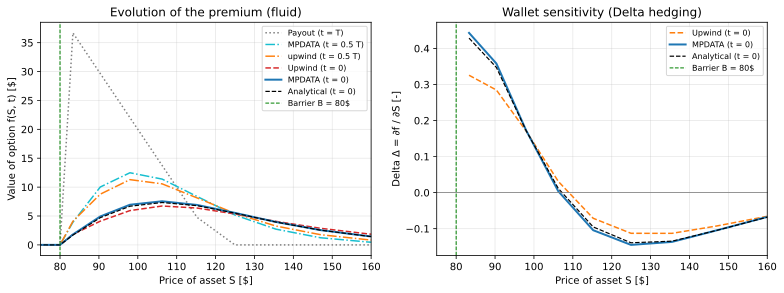

Results for nx=75 and nt=750.


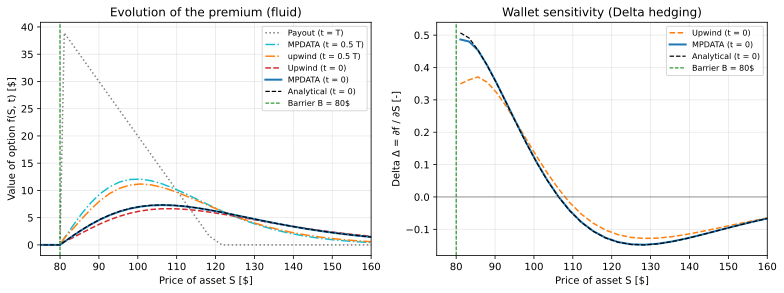

In [ ]:
strike_price = 120
barrier_price = 80
volatility = 35 / 100
risk_free_interest_rate = 5 / 100
T = 0.5
nx = [25, 75, 125, 200]
nt = [250, 750, 1000]
outfreq = [25, 75, 10]

for i in range(0, 3):
    integ_MPDATA = DownAndOutPutIntegrator(
            strike_price=strike_price, 
            barrier_price=barrier_price,
            volatility=volatility, 
            risk_free_interest_rate=risk_free_interest_rate,
            nx=nx[i])
    integ_upwind = DownAndOutPutIntegrator(
            strike_price=strike_price, 
            barrier_price=barrier_price,
            volatility=volatility, 
            risk_free_interest_rate=risk_free_interest_rate,
            nx=nx[i],
            options=Options(n_iters=1))
    
    output_MPDATA = integ_MPDATA(nt=nt[i], T=T, outfreq=outfreq[i])
    output_upwind = integ_upwind(nt=nt[i], T=T, outfreq=outfreq[i])
    print(f"Results for nx={nx[i]} and nt={nt[i]}.")
    plot_results(integ_MPDATA, output_MPDATA, output_upwind)

## 4. Wyniki: ewolucja wartości opcji i wrażliwość Delta (dla nx=200, nt=4000, outfreq=200)

In [ ]:
dt_frame = T / (len(output_MPDATA) - 1)
y_max = np.max(output_MPDATA[0]) * 1.1
S = integ_MPDATA.S
S_plot = np.concatenate(([60.0, barrier_price], S))
pad_zeros = lambda arr: np.concatenate(([0.0, 0.0], arr))
analytical_price = AnalyticalDownAndOutPutSolver(S, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
print(f"Animation done for nx={nx[-1]} and nt={nt[-1]}.")

def plot(frame):
    fig, ax = pyplot.subplots(figsize=(7, 4))
    tau = frame * dt_frame
    t_remaining = T - tau
    ax.fill_between(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', alpha=0.25)
    ax.plot(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', linewidth=2, label='MPDATA')
    ax.plot(S_plot, pad_zeros(output_upwind[frame]), color='tab:orange', linestyle='--', linewidth=1.5, label='Upwind')
    ax.plot(S_plot, pad_zeros(analytical_price), color='black', linestyle=':', linewidth=1.2, label='Analytical goal (t = 0)')
    ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Barrier B = {barrier_price}$')
    ax.set_xlim(65, 200)
    ax.set_ylim(-1, y_max)
    ax.set_xlabel('Price of asset S [$]')
    ax.set_ylabel('Value of option [$]')
    ax.set_title(f'Payout function through time - {t_remaining:.3f} years remaining')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    return fig

show_anim(plot, range(len(output_MPDATA)))

### Wnioski
* **Wpływ bariery wyłączającej na wycenę:** W trakcie cofania czasu od $t = T$ do $t = 0$ dyfuzja odprowadza wartość opcji przez pochłaniający brzeg $B = 80\$$, co obniża dzisiejszą cenę (*premium*) instrumentu względem klasycznej opcji europejskiej i wymusza zerowanie się krzywej wyceny na barierze.
* **Porównanie schematów (`MPDATA` vs `upwind`):** Schemat pierwszego rzędu `upwind` wprowadza silną dyfuzję numeryczną, przez co sztucznie zaniża maksimum ceny opcji w okolicach $S \approx 95\$$ oraz wygładza pochodną $\Delta = \partial V / \partial S$ w pobliżu bariery. Algorytm `MPDATA` (`n_iters=2`) skutecznie redukuje rozmycie numeryczne i bardzo dobrze odtwarza przebieg ścisłego rozwiązania analitycznego zarówno dla ceny opcji, jak i współczynnika *Delta hedgingu*.